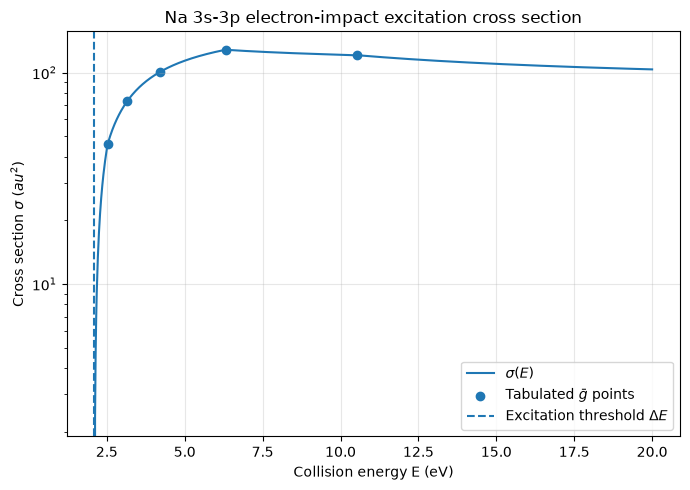

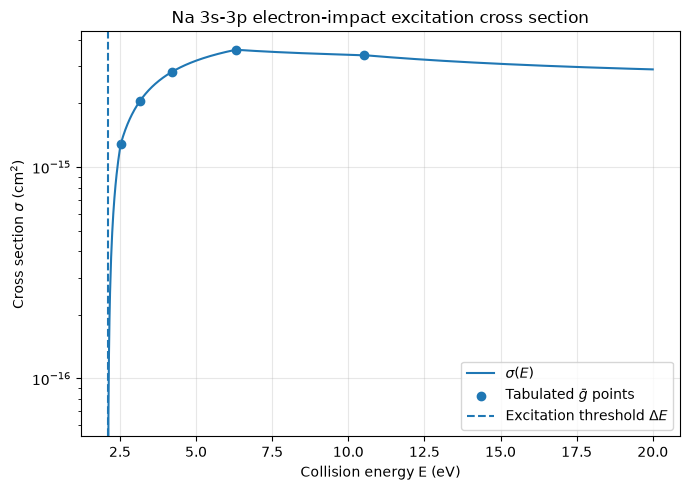

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------
# Constants / Na D transition data
# -------------------------------------------------

DeltaE_eV = 2.104       # approximate common 3s -> 3p excitation energy
f_if = 0.961            # f_D1 + f_D2

hartree_to_eV = 27.2114
a0_cm = 5.29177e-9

# excitation energy in atomic units
DeltaE_au = DeltaE_eV / hartree_to_eV


# -------------------------------------------------
# van Regemorter g-bar table for neutral atoms
# -------------------------------------------------

x_table = np.array([
    1.0, 1.2, 1.5, 2.0, 3.0,
    5.0, 10.0, 30.0, 100.0
])

gbar_table = np.array([
    0.00, 0.03, 0.06, 0.11, 0.21,
    0.33, 0.56, 0.98, 1.33
])


# -------------------------------------------------
# Collision-energy range
# -------------------------------------------------

E_eV = np.linspace(DeltaE_eV, 20.0, 1000)

# x = E / DeltaE
x = E_eV / DeltaE_eV

# interpolate g-bar
gbar = np.interp(x, x_table, gbar_table)


# -------------------------------------------------
# Collision energy in atomic units
# -------------------------------------------------

E_au = E_eV / hartree_to_eV


# -------------------------------------------------
# van Regemorter cross section
#
# sigma = (2*pi^2/sqrt(3))
#         * (1/E)
#         * (1/DeltaE)
#         * f_if
#         * gbar
#
# energies must be in atomic units
# result is in a0^2
# -------------------------------------------------

sigma_au = (
    (2 * np.pi**2 / np.sqrt(3))
    * (1 / E_au)
    * (1 / DeltaE_au)
    * f_if
    * gbar
)


# Convert a0^2 -> cm^2
sigma_cgs = sigma_au * a0_cm**2


# -------------------------------------------------
# Plot 1: atomic units
# -------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(E_eV, sigma_au, label=r'$\sigma(E)$')

# show original g-bar table points
E_table_eV = x_table * DeltaE_eV

sigma_table_au = (
    (2 * np.pi**2 / np.sqrt(3))
    * (1 / (E_table_eV / hartree_to_eV))
    * (1 / DeltaE_au)
    * f_if
    * gbar_table
)

# only show table points inside plotted energy range
mask = E_table_eV <= 20

plt.scatter(
    E_table_eV[mask],
    sigma_table_au[mask],
    label=r'Tabulated $\bar{g}$ points'
)

plt.axvline(
    DeltaE_eV,
    linestyle='--',
    label=r'Excitation threshold $\Delta E$'
)

plt.xlabel('Collision energy E (eV)')
plt.ylabel(r'Cross section $\sigma$ ($au^2$)')
plt.title('Na 3s-3p electron-impact excitation cross section')
plt.grid(alpha=0.3)
plt.yscale('log')
plt.legend()
plt.tight_layout()

plt.savefig('Na_cross_section_atomic_units.png', dpi=300)
plt.show()


# -------------------------------------------------
# Plot 2: CGS units
# -------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(E_eV, sigma_cgs, label=r'$\sigma(E)$')

sigma_table_cgs = sigma_table_au * a0_cm**2

plt.scatter(
    E_table_eV[mask],
    sigma_table_cgs[mask],
    label=r'Tabulated $\bar{g}$ points'
)

plt.axvline(
    DeltaE_eV,
    linestyle='--',
    label=r'Excitation threshold $\Delta E$'
)

plt.xlabel('Collision energy E (eV)')
plt.ylabel(r'Cross section $\sigma$ (cm$^2$)')
plt.title('Na 3s-3p electron-impact excitation cross section')
plt.grid(alpha=0.3)
plt.yscale('log')
plt.legend()
plt.tight_layout()

plt.savefig('Na_cross_section_CGS.png', dpi=300)
plt.show()